# Brittle fracture: from stiffness and cleavage to lattice trapping

A brittle crack is described at two scales at once. Far from the tip the solid
is a linear elastic continuum, and the load on the crack is one number, the
stress intensity factor $K_I$. At the tip, bonds break one at a time, and
whether the crack moves is decided by atoms. Linear elastic fracture mechanics
(LEFM) joins the two with an energy balance: the crack can advance when the
elastic energy it releases per unit area, $G$, pays for the two surfaces it
creates,

$$G(K_G) = 2\gamma ,$$

which defines the **Griffith load** $K_G$. Every input to that balance is a
property of the bulk crystal: the elastic constants that convert $K$ into $G$,
and the surface energy $\gamma$ of the plane that cleaves.

$K_G$ is not where a real lattice crack moves. Because the lattice is
discrete, an atomically sharp crack sits in a periodic energy landscape and
stays put over a range of loads — **lattice trapping** (Thomson, Hsieh and
Rana 1971). It advances at $K_+ > K_G$ and heals at $K_- < K_G$, and both ends
of $[K_-, K_+]$ are points where the equilibrium branch of the crack ceases to
exist: *folds* of a load-driven solution branch.

`mv.mech` supplies the pieces such a calculation is built from, each acting
on one ASE structure or one function rather than on a dataset:

| step | function |
|---|---|
| relaxed-ion (and clamped-ion) elastic constants | `mv.mech.elastic_constants` |
| every termination of a cleavage plane, and its $\gamma$ | `mv.mech.cleavage_energies` |
| audit of hand-written forces / stresses | `mv.mech.check_gradient` |
| locating the end of an equilibrium branch in the load | `mv.mech.bracket_fold` |

The crystal is diamond-structure silicon, described by the Tersoff potential
(Tersoff 1988, the "T3" Si parametrisation) — ASE's native implementation, so
nothing is downloaded and every cell runs in seconds.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ase.build import bulk
from ase.calculators.emt import EMT
from ase.calculators.tersoff import Tersoff, TersoffParameters
from scipy.optimize import minimize_scalar

import matverse as mv

mv.pl.set_style()
T_START = time.time()

🔬 Starting plot initialization...
🧪 Calculators available: 12
    • emt — EMT (LGPL-2.1)
    • lj — Lennard-Jones (LGPL-2.1)
    • mace-mpa — mace-mpa (unstated)
    • mace-omat — mace-omat (unstated)
    • sevennet — sevennet (unstated)
    • chgnet — chgnet (unstated)
    • m3gnet — m3gnet (unstated)
    • m3gnet-r2scan — m3gnet-r2scan (unstated)
    • tensornet — tensornet (unstated)
    • orb — orb (unstated)
    • gpaw-pbe — gpaw-pbe (unstated)
    • gpaw-pbe-fast — gpaw-pbe-fast (unstated)


🚫 No GPU found — CPU only. Fine for EMT, slow for a machine-learned potential.

                   __
   ____ ___  ____ _/ /__   _____  _____________
  / __ `__ \/ __ `/ __/ | / / _ \/ ___/ ___/ _ \
 / / / / / / /_/ / /_ | |/ /  __/ /  (__  )  __/
/_/ /_/ /_/\__,_/\__/ |___/\___/_/  /____/\___/

🔖 Version: 0.1.72   🧮 Functions: 282   📚 Tutorials: https://matverse.readthedocs.io/
✅ set_style complete.



## A potential, and one defect in its implementation

The T3 parameters are typed in below in ASE's (LAMMPS-style) order. One
detail has to be dealt with first. Tersoff's bond order is
$b_{ij} = (1 + \beta^n \zeta_{ij}^n)^{-1/2n}$, where $\zeta_{ij}$ sums over
the *other* neighbours $k$ of atom $i$. For T3, $n = 0.787 < 1$, so
$\partial b/\partial\zeta \propto \zeta^{n-1}$ diverges at $\zeta = 0$ — which
is exactly the value for an atom left with a single neighbour, as on a
freshly cut surface. ASE 3.29 evaluates that power literally and raises
`ZeroDivisionError`. The derivative is only ever multiplied by
$\partial\zeta/\partial r$, which is identically zero when there is no third
atom, so the right contribution is zero; the subclass below says so. A patch
like this is a hand-written change to a force routine — the kind of thing
`mv.mech.check_gradient` exists to audit, and we will audit it on a cut
surface further down.

In [2]:
SI_T3 = TersoffParameters(m=3.0, gamma=1.0, lambda3=0.0, c=1.0039e5, d=16.217,
                          h=-0.59825, n=0.78734, beta=1.1e-6, lambda2=1.7322,
                          B=471.18, R=2.85, D=0.15, lambda1=2.4799, A=1830.8)


class GuardedTersoff(Tersoff):
    """Tersoff with d b_ij / d zeta set to 0 where zeta == 0 (no third atom)."""

    def _calc_bij_d(self, zeta, beta, n):
        if zeta == 0.0:
            return 0.0
        return super()._calc_bij_d(zeta, beta, n)


calc = GuardedTersoff({("Si", "Si", "Si"): SI_T3})


def energy_per_atom(a):
    cell = bulk("Si", "diamond", a=a, cubic=True)
    cell.calc = calc
    return cell.get_potential_energy() / len(cell)


opt = minimize_scalar(energy_per_atom, bracket=(5.35, 5.43, 5.50), tol=1e-10)
a0 = float(opt.x)
si = bulk("Si", "diamond", a=a0, cubic=True)
si.calc = calc
print(f"lattice constant a0 = {a0:.4f} A   cohesive energy = {-opt.fun:.3f} eV/atom")

lattice constant a0 = 5.4320 A   cohesive energy = 4.630 eV/atom


$a_0 = 5.432$ Å and $E_\mathrm{coh} = 4.63$ eV/atom are the values Tersoff
fitted. The reference cell is now stress-free *for this potential*, which
matters: a stiffness taken about a stressed reference carries the stress in
it.

## 1. Elastic constants: clamped ions, relaxed ions, and Cauchy–Born

**Principle.** The Cauchy–Born rule says that a crystal under a homogeneous
deformation gradient $F$ deforms like its lattice: every lattice vector
$\mathbf{R} \mapsto F\mathbf{R}$. In a *Bravais* lattice (one atom per
primitive cell, e.g. fcc Cu) that fixes every atom. In a *multilattice* —
diamond has two interpenetrating fcc sublattices — it fixes only the cells;
the sublattices can still shift against each other by an **inner
displacement** $\mathbf{u}$, and under most strains they do. The energy
density of the continuum is then

$$W(F) = \min_{\mathbf{u}} \, W(F, \mathbf{u}),$$

and its second derivative is the **relaxed-ion** stiffness

$$C_{ij} = C^{0}_{ij} - \Lambda_{ki}\,(\Phi^{-1})_{kl}\,\Lambda_{lj},$$

where $C^0$ is the clamped-ion stiffness (sublattices dragged rigidly with the
strain), $\Phi$ the force-constant matrix of the inner displacement and
$\Lambda$ the force on the sublattices per unit strain. The correction is
positive semi-definite: relaxing ions can only soften. In diamond, a shear
$\varepsilon_{yz}$ pushes the two sublattices apart along $x$ (Kleinman's
internal strain), so $C_{44}$ is where the correction lives; $C_{11}$ and
$C_{12}$ are untouched because a uniaxial strain along a cube axis leaves every
atom on a site of inversion-related symmetry.

This is the "multilattice Cauchy–Born" correction. Any continuum that is
meant to be in equilibrium with its own atoms — the LEFM far field around a
crack, the boundary condition of a flexible-boundary cluster — must use the
relaxed-ion constants; the clamped ones describe a crystal whose sublattices
are held by an external agent.

**Method.** `mv.mech.elastic_constants` applies $\pm\varepsilon$ for each of the
six Voigt strains, relaxes the atomic positions at fixed strained cell
(`relax_internal=True`, the default) and takes the central difference of the
stress. `also_clamped=True` repeats it without the inner relaxation.

In [3]:
res = mv.mech.elastic_constants(si, calc, strain=1e-3, also_clamped=True, fmax=1e-6)

table = pd.DataFrame({
    "relaxed-ion": [res["C11"], res["C12"], res["C44"], res["bulk_modulus"]],
    "clamped-ion": [res["clamped"][k] for k in ("C11", "C12", "C44", "bulk_modulus")],
}, index=["C11", "C12", "C44", "B"]).round(1)
print(table)
print(f"inner relaxations converged: {res['all_inner_relaxations_converged']}, "
      f"max residual inner force {res['max_inner_force']:.1e} eV/A")
print(f"residual stress of the reference: {np.abs(res['residual_stress']).max():.1e} GPa, "
      f"deviation from cubic form: {res['max_deviation_from_cubic']:.1e} GPa")

     relaxed-ion  clamped-ion
C11        142.5        142.5
C12         75.4         75.4
C44         69.0        118.8
B           97.8         97.8
inner relaxations converged: True, max residual inner force 1.3e-08 eV/A
residual stress of the reference: 5.0e-08 GPa, deviation from cubic form: 2.6e-11 GPa


As a control, the same call on a Bravais lattice — fcc copper with ASE's
EMT — must give identical relaxed and clamped tensors, because there is
nothing for the ions to relax into.

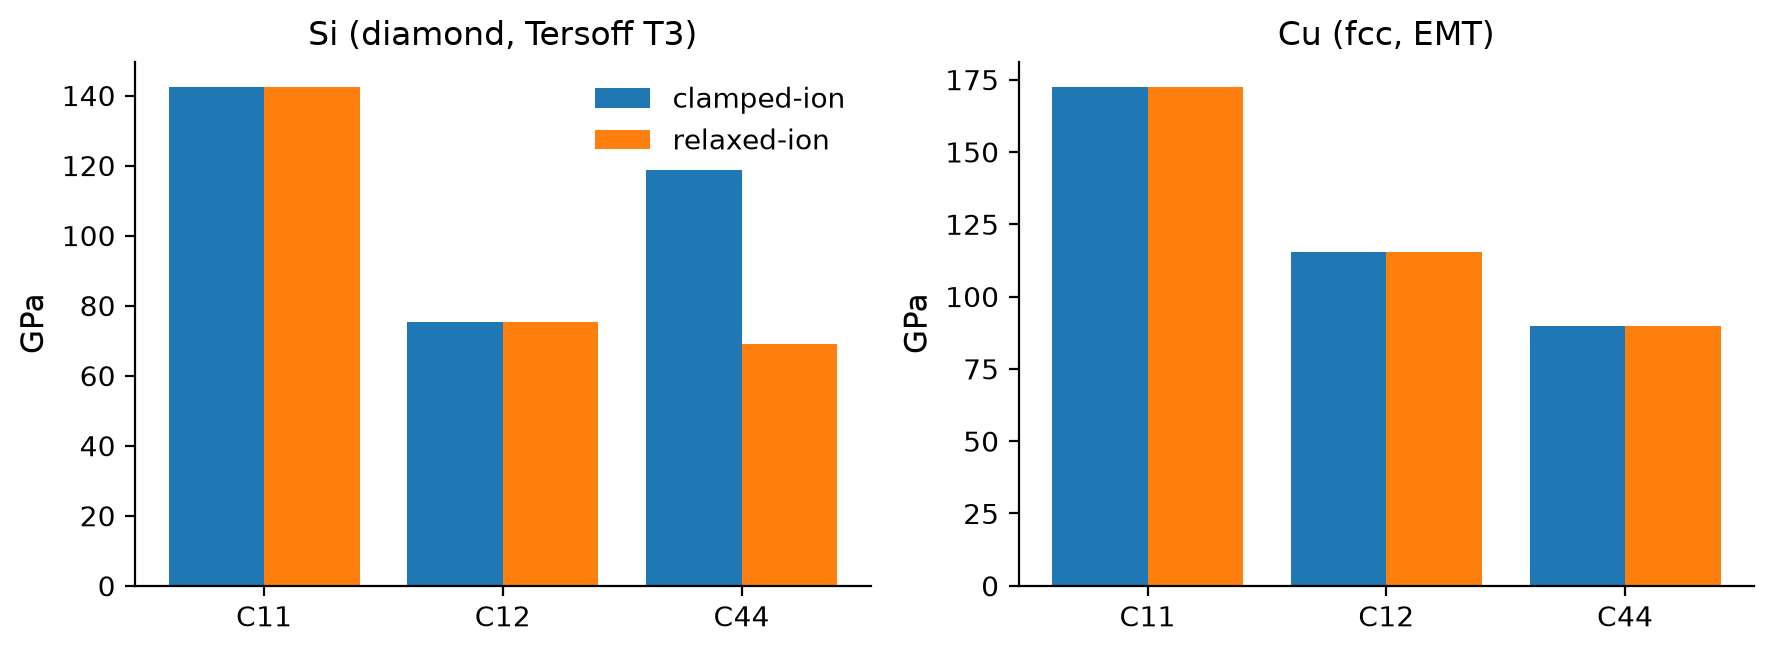

Cu: C44 relaxed / clamped = 1.0
Si: C44 relaxed / clamped = 0.581


In [4]:
def emt_energy(a):
    cell = bulk("Cu", "fcc", a=a, cubic=True)
    cell.calc = EMT()
    return cell.get_potential_energy()


a_cu = float(minimize_scalar(emt_energy, bracket=(3.55, 3.60, 3.65), tol=1e-10).x)
cu = bulk("Cu", "fcc", a=a_cu, cubic=True)
res_cu = mv.mech.elastic_constants(cu, EMT(), also_clamped=True)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=False)
for ax, r, title in [(axes[0], res, "Si (diamond, Tersoff T3)"),
                     (axes[1], res_cu, "Cu (fcc, EMT)")]:
    keys = ["C11", "C12", "C44"]
    x = np.arange(3)
    ax.bar(x - 0.2, [r["clamped"][k] for k in keys], 0.4, label="clamped-ion")
    ax.bar(x + 0.2, [r[k] for k in keys], 0.4, label="relaxed-ion")
    ax.set_xticks(x, keys)
    ax.set_ylabel("GPa")
    ax.set_title(title)
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()
print("Cu: C44 relaxed / clamped =", round(res_cu["C44"] / res_cu["clamped"]["C44"], 4))
print("Si: C44 relaxed / clamped =", round(res["C44"] / res["clamped"]["C44"], 3))

**Reading it.** For Si the relaxed-ion constants are $C_{11} \approx 143$,
$C_{12} \approx 75$, $C_{44} \approx 69$ GPa — the values published for this
parametrisation — against $C^0_{44} \approx 119$ GPa with the sublattices
clamped: inner relaxation removes ~40 % of the shear stiffness and leaves
$C_{11}$, $C_{12}$ and the bulk modulus untouched, exactly the pattern the
symmetry argument predicts. For Cu the two tensors coincide to numerical
precision. (Measured Si: $C_{11} = 166$, $C_{12} = 64$, $C_{44} = 80$ GPa —
the potential's error is a separate question from the method's.)

## 2. Cleavage energy: which cut of a plane

**Principle.** A plane family $(hkl)$ can often be cut in more than one place.
Diamond {111} planes come in closely spaced *bilayers*: between bilayers the
gap is wide and one bond per surface atom crosses it (the **shuffle** cut);
inside a bilayer the gap is narrow and three bonds cross it (the **glide**
cut). A crack follows the cheaper one, so the $\gamma$ in Griffith's balance is
the *minimum* over terminations:

$$\gamma = \frac{E_\mathrm{slab} - N\,e_\mathrm{bulk}}{2A}.$$

**Method.** `mv.mech.cleavage_energies` builds the smallest periodic cell
oriented along $(hkl)$, enumerates each inequivalent inter-plane gap, opens a
vacuum there, and returns $\gamma$ unrelaxed and after relaxing positions
(local relaxation only — no reconstruction search), lowest first. The bulk
reference $e_\mathrm{bulk}$ comes from the same oriented cell, so the two
energies are consistent.

In [5]:
rows = []
cuts = {}
for miller in [(1, 1, 1), (1, 1, 0)]:
    cuts[miller] = mv.mech.cleavage_energies(si, miller, calc, min_thickness=15.0,
                                             vacuum=12.0)
    for c in cuts[miller]:
        rows.append({"plane": str(miller), "gap (A)": round(c["gap"], 3),
                     "gamma unrelaxed (J/m2)": round(c["gamma_unrelaxed"], 3),
                     "gamma relaxed (J/m2)": round(c["gamma_relaxed"], 3),
                     "atoms": c["n_atoms"], "converged": c["converged"]})
pd.DataFrame(rows)

,plane,gap (A),gamma unrelaxed (J/m2),gamma relaxed (J/m2),atoms,converged
0,"(1, 1, 1)",2.352,1.286,1.200,48,True
1,"(1, 1, 1)",0.784,4.145,4.139,48,True
2,"(1, 1, 0)",1.921,1.575,1.522,32,True


**Reading it.** (111) has two cuts. The wide gap ($\approx a_0\sqrt3/4 =
2.35$ Å, the shuffle cut) costs $\approx 1.2$ J/m² relaxed; the narrow one
($0.78$ Å, glide) cuts three bonds per atom and costs over three times as
much — the ratio close to 3 is bond counting. (110) has a single cut at
$\approx 1.5$ J/m², above the (111) shuffle value, in line with {111} being
silicon's preferred cleavage plane. The experimental Si(111) fracture surface
energy is ~1.1–1.2 J/m².

## 3. The Griffith load in an anisotropic crystal

**Principle.** For a crack in an anisotropic solid, $G$ is still quadratic in
$K_I$, but the coefficient depends on the crack orientation. Take $x$ along
the propagation direction, $y$ along the crack-plane normal, $z$ along the
front, and let $s_{ij}$ be the compliance in that frame. When the $x$–$y$ plane
is a mirror plane (in-plane and antiplane deformation decouple), the
plane-strain compliances $b_{ij} = s_{ij} - s_{i3}s_{j3}/s_{33}$ define the
Lekhnitskii characteristic equation

$$b_{11}\mu^4 - 2b_{16}\mu^3 + (2b_{12} + b_{66})\mu^2 - 2b_{26}\mu + b_{22} = 0,$$

and with $\mu_1, \mu_2$ its roots in the upper half-plane (Sih, Paris and
Irwin 1965)

$$G = -\tfrac12 K_I^2\, b_{22}\, \mathrm{Im}\!\left[\frac{\mu_1 + \mu_2}{\mu_1\mu_2}\right]
\equiv \frac{K_I^2}{E^*}, \qquad K_G = \sqrt{2\gamma E^*}.$$

For an isotropic solid $\mu_1 = \mu_2 = i$ and $E^* = E/(1-\nu^2)$. The cell
below implements this in a few lines of numpy, checks it against the isotropic
limit, and evaluates the two classic silicon crack systems: (111) plane with
a $[1\bar10]$ front, and (110) plane with a $[001]$ front.

In [6]:
VOIGT = [(0, 0), (1, 1), (2, 2), (1, 2), (0, 2), (0, 1)]


def rotate_voigt(C, Q):
    """6x6 stiffness in the frame whose axes are the rows of Q."""
    full = np.zeros((3, 3, 3, 3))
    for I, (i, j) in enumerate(VOIGT):
        for J, (k, l) in enumerate(VOIGT):
            for a, b in {(i, j), (j, i)}:
                for c, d in {(k, l), (l, k)}:
                    full[a, b, c, d] = C[I, J]
    rot = np.einsum("ia,jb,kc,ld,abcd->ijkl", Q, Q, Q, Q, full)
    return np.array([[rot[i, j, k, l] for (k, l) in VOIGT] for (i, j) in VOIGT])


def crack_modulus(C_gpa, x, y, z):
    """Effective modulus E* (GPa) with G = K^2 / E* for a plane-strain mode-I crack."""
    Q = np.array([np.asarray(v, float) / np.linalg.norm(v) for v in (x, y, z)])
    s = np.linalg.inv(rotate_voigt(C_gpa, Q))           # Voigt order 1..6 = xx..xy
    coupling = np.abs(s[np.ix_([0, 1, 5], [3, 4])]).max() / np.abs(s).max()
    assert coupling < 1e-8, "x-y is not a mirror plane: in/antiplane couple"
    b = lambda i, j: s[i, j] - s[i, 2] * s[j, 2] / s[2, 2]   # noqa: E731
    roots = np.roots([b(0, 0), -2 * b(0, 5), 2 * b(0, 1) + b(5, 5), -2 * b(1, 5), b(1, 1)])
    upper = roots[roots.imag > 0]
    mu1, mu2 = (upper[0], upper[0]) if len(upper) == 1 else upper[:2]
    inv_E = -0.5 * b(1, 1) * np.imag((mu1 + mu2) / (mu1 * mu2))
    return 1.0 / inv_E


def griffith_K(gamma_J_m2, E_star_gpa):
    """K_G in MPa m^1/2."""
    return np.sqrt(2.0 * gamma_J_m2 * E_star_gpa * 1e9) / 1e6


# isotropic check: E = 150 GPa, nu = 0.25 -> E* = E / (1 - nu^2)
E, nu = 150.0, 0.25
lam, mu_s = E * nu / ((1 + nu) * (1 - 2 * nu)), E / (2 * (1 + nu))
C_iso = np.zeros((6, 6)); C_iso[:3, :3] = lam
C_iso[np.arange(3), np.arange(3)] = lam + 2 * mu_s; C_iso[3:, 3:] = np.eye(3) * mu_s
C_iso[:3, :3] += np.eye(3) * 1e-9 * E                    # break the exact degeneracy
print("isotropic E*:", round(crack_modulus(C_iso, [1, 0, 0], [0, 1, 0], [0, 0, 1]), 3),
      " expected", round(E / (1 - nu ** 2), 3))

SYSTEMS = {"(111)[1-10]": ([1, 1, -2], [1, 1, 1], [1, -1, 0], (1, 1, 1)),
           "(110)[001]": ([1, -1, 0], [1, 1, 0], [0, 0, 1], (1, 1, 0))}
griffith = {}
for name, (x, y, z, miller) in SYSTEMS.items():
    E_star = crack_modulus(res["C"], x, y, z)
    gamma = cuts[miller][0]["gamma_relaxed"]
    griffith[name] = {"E* (GPa)": E_star, "gamma (J/m2)": gamma,
                      "K_G (MPa m^1/2)": griffith_K(gamma, E_star)}
pd.DataFrame(griffith).T.round(3)

isotropic E*: 160.0  expected 160.0


,E* (GPa),gamma (J/m2),K_G (MPa m^1/2)
(111)[1-10],149.114,1.200,0.598
(110)[001],131.737,1.522,0.633


**Reading it.** The isotropic limit is reproduced, so the formula and the
tensor rotation are consistent. For the (111)$[1\bar10]$ crack,
$K_G \approx 0.60$ MPa m$^{1/2}$ with T3. The (110)$[001]$ crack sees a
*softer* effective modulus but a higher $\gamma$, and the surface energy wins:
its $K_G$ is higher, which is why (111) is the cleavage plane. Measured Si fracture toughness is
~0.7–0.9 MPa m$^{1/2}$ on {111}; the gap reflects both the potential and the
lattice trapping that $K_G$ ignores, to which we come in section 5.

### Pitfalls: the wrong constants and the wrong cut

Two errors give a plausible-looking $K_G$ without any warning: using the
clamped-ion tensor for the continuum, and taking $\gamma$ from a cut that is
not the lowest one (here the glide cut, which is what one gets by cleaving a
slab "between two atomic planes" without enumerating the gaps).

In [7]:
x, y, z, miller = SYSTEMS["(111)[1-10]"]
right = griffith["(111)[1-10]"]["K_G (MPa m^1/2)"]
E_clamped = crack_modulus(res["clamped"]["C"], x, y, z)
k_clamped = griffith_K(cuts[miller][0]["gamma_relaxed"], E_clamped)
k_glide = griffith_K(cuts[miller][-1]["gamma_relaxed"], crack_modulus(res["C"], x, y, z))
for label, k in [("relaxed-ion C, shuffle cut (correct)", right),
                 ("clamped-ion C, shuffle cut", k_clamped),
                 ("relaxed-ion C, glide cut", k_glide)]:
    print(f"{label:40s} K_G = {k:.3f} MPa m^1/2   ({100 * (k / right - 1):+.1f} %)")

relaxed-ion C, shuffle cut (correct)     K_G = 0.598 MPa m^1/2   (+0.0 %)
clamped-ion C, shuffle cut               K_G = 0.689 MPa m^1/2   (+15.1 %)
relaxed-ion C, glide cut                 K_G = 1.111 MPa m^1/2   (+85.7 %)


The clamped tensor makes the crystal look stiffer and inflates $K_G$ by about
15 % — small enough to pass a casual sanity check against experiment, and
comparable to the width of a lattice-trapping range. The wrong cut overestimates $K_G$ by
almost a factor of two.

## 4. Auditing forces and stresses: `check_gradient`

**Principle.** A coupled atomistic model — a crack cluster embedded in a
continuum, with extra degrees of freedom for the far field — is driven by
derivatives somebody derived by hand: forces, configurational forces,
stresses. A wrong derivative still lets a minimiser stop somewhere; it just
stops in the wrong place. The cheapest defence is a central difference,

$$\frac{\partial E}{\partial x_i} \approx \frac{E(x + h e_i) - E(x - h e_i)}{2h},
\qquad \text{error} \sim h^2 E''' + \epsilon_\mathrm{mach} E / h .$$

The truncation part shrinks as $h^2$; a real bug does not shrink at all. So the
test is: check at two values of $h$.

**Method.** `mv.mech.check_gradient(energy, x, analytic=...)` samples
components of $x$, computes the central difference of `energy` and reports the
worst relative and absolute error. Forces are minus the gradient — pass
`sign=-1`. We check the guarded Tersoff forces on a rattled bulk cell and on
the *glide-cut surface*, where the patched branch $\zeta = 0$ is exercised,
and the stress by differentiating the energy with respect to a homogeneous
strain: $\partial E / \partial \varepsilon_{ij} = V \sigma_{ij}$.

In [8]:
from ase.stress import voigt_6_to_full_3x3_stress


def position_energy(atoms):
    def energy(positions):
        trial = atoms.copy(); trial.positions = positions; trial.calc = calc
        return trial.get_potential_energy()
    return energy


bulk16 = si.repeat((2, 1, 1)); bulk16.rattle(0.05, seed=1); bulk16.calc = calc
glide = cuts[(1, 1, 1)][-1]["slab"].copy(); glide.rattle(0.02, seed=2); glide.calc = calc
for label, atoms in [("rattled bulk", bulk16), ("glide-cut slab (zeta = 0 atoms)", glide)]:
    rep = mv.mech.check_gradient(position_energy(atoms), atoms.positions,
                                 analytic=atoms.get_forces(), sign=-1, n_samples=24)
    print(f"forces, {label:32s} max rel err {rep['max_rel_err']:.1e}  "
          f"max abs err {rep['max_abs_err']:.1e} eV/A")

strained = bulk16.copy(); strained.set_cell(strained.cell * 1.01, scale_atoms=True)
strained.calc = calc
cell0 = np.asarray(strained.get_cell())


def strain_energy(eps):
    trial = strained.copy()
    trial.set_cell(cell0 @ (np.eye(3) + eps).T, scale_atoms=True); trial.calc = calc
    return trial.get_potential_energy()


virial = strained.get_volume() * voigt_6_to_full_3x3_stress(strained.get_stress())
rep = mv.mech.check_gradient(strain_energy, np.zeros((3, 3)), analytic=virial,
                             indices=range(9), h=1e-5)
print(f"stress (V sigma = dE/d eps)                max rel err {rep['max_rel_err']:.1e}")

forces, rattled bulk                     max rel err 8.0e-07  max abs err 9.4e-09 eV/A


forces, glide-cut slab (zeta = 0 atoms)  max rel err 1.6e-06  max abs err 7.3e-08 eV/A


stress (V sigma = dE/d eps)                max rel err 1.6e-08


All three agree to $10^{-6}$ or better: the guarded potential is consistent,
including on the surface atoms the guard affects.

### Pitfall: telling a bug from truncation

To see what a failure looks like, here is a hand-written Morse cluster
energy with two force routines: a correct one, and one with a classic slip —
the derivative of $e^{-2\alpha(r-r_0)}$ written without its factor 2. Both are
checked at three step sizes.

In [9]:
D_M, ALPHA, R0 = 0.35, 1.36, 2.87       # a Morse pair; parameters only set the scale


def morse_energy(pos):
    d = pos[:, None, :] - pos[None, :, :]
    r = np.linalg.norm(d, axis=-1)[np.triu_indices(len(pos), 1)]
    e = np.exp(-ALPHA * (r - R0))
    return float(np.sum(D_M * (e ** 2 - 2 * e)))


def morse_forces(pos, buggy=False):
    d = pos[:, None, :] - pos[None, :, :]
    r = np.linalg.norm(d, axis=-1); np.fill_diagonal(r, np.inf)
    e = np.exp(-ALPHA * (r - R0))
    dEdr = D_M * ((1.0 if buggy else 2.0) * -ALPHA * e ** 2 + 2 * ALPHA * e)
    return -np.sum((dEdr / r)[:, :, None] * d, axis=1)


rng = np.random.default_rng(0)
cluster = bulk("Cu", "fcc", a=4.06).repeat((2, 2, 2)).positions + rng.normal(0, 0.05, (8, 3))
rows = []
for h in [1e-2, 1e-3, 1e-4]:
    for buggy in (False, True):
        rep = mv.mech.check_gradient(morse_energy, cluster, sign=-1, h=h, n_samples=24,
                                     analytic=morse_forces(cluster, buggy))
        rows.append({"h": h, "forces": "buggy" if buggy else "correct",
                     "max_rel_err": rep["max_rel_err"]})
pd.DataFrame(rows).pivot(index="h", columns="forces", values="max_rel_err")

forces,buggy,correct
h,,
0.0001,210.053773,0.000001
0.0010,210.079156,0.000121
0.0100,212.648706,0.012296


The correct routine's error falls a hundredfold per decade of $h$ —
truncation, $\propto h^2$. The buggy one's error is the same at every $h$ —
that is a wrong derivative, and no choice of step will hide it. (Making $h$
very small eventually brings round-off back, $\propto 1/h$; for energies of a
few thousand atoms in double precision, $10^{-4}$–$10^{-3}$ Å is the useful
window.)

## 5. Folds of a load-driven branch: `bracket_fold`

**Principle.** A quasi-static calculation follows an equilibrium state
$x^*(K)$ as the load $K$ changes, warm-starting each solve from the last
solution. The branch ends at a **fold** (turning point), where the
equilibrium merges with a saddle and the Hessian becomes singular; beyond it
the solver either fails or lands somewhere else. Crack advance and healing,
snap-through and buckling are all folds, and the lattice-trapping range
$[K_-, K_+]$ is the pair of folds of the branch "crack tip in this lattice
cell".

**A model with a known answer.** Thomson's picture reduces the crack to its
tip position $\xi$ (in units of the lattice period) moving in a periodic
bond-breaking landscape, tilted by the mismatch between released and
consumed energy. Per unit front and in units of $2\gamma a$,

$$\Pi(\xi; K) = \left(1 - \frac{K^2}{K_G^2}\right)\xi - \frac{w}{2\pi}\cos 2\pi\xi ,$$

with $w$ the depth of the lattice corrugation relative to $2\gamma$. Equilibria
satisfy $(1 - K^2/K_G^2) + w \sin 2\pi\xi = 0$ and exist only while
$|K^2/K_G^2 - 1| \le w$, so the folds are exactly

$$K_\pm = K_G\sqrt{1 \pm w}.$$

In an atomistic crack calculation $w$ is not a parameter but the outcome —
the state is the cluster's positions and the solve a full relaxation — but
the bracketing logic is identical, and here we can check it. We use $K_G$
from section 3 and take $w = 0.3$ as the model's corrugation.

**Method.** `mv.mech.bracket_fold(solve, load0, state0, step, jump, ...)` ramps
the load from a converged seed. A new load is on the branch when the solver
converged *and* the state moved by at most `jump` from the previous on-branch
state; the first failure is bisected against the last success down to
`resolution`. Every probe is warm-started from the last on-branch state, so
the bracket belongs to the branch, not to the solver. `direction=+1` finds the
upper fold, `-1` the lower one.

In [10]:
K_G = griffith["(111)[1-10]"]["K_G (MPa m^1/2)"]
W = 0.3


def gradient(xi, K):
    return (1 - (K / K_G) ** 2) + W * np.sin(2 * np.pi * xi)


def curvature(xi):
    return 2 * np.pi * W * np.cos(2 * np.pi * xi)


def solve(K, guess):
    """Local minimisation from guess: damped Newton where convex, descent otherwise."""
    xi = float(np.asarray(guess).ravel()[0])
    for _ in range(2000):
        g, c = gradient(xi, K), curvature(xi)
        if abs(g) < 1e-12 and c > 0:
            break
        xi -= np.clip(g / c, -0.05, 0.05) if c > 1e-9 else 0.05 * np.sign(g)
    ok = abs(gradient(xi, K)) < 1e-10 and curvature(xi) > 0
    return np.array([xi]), bool(ok)


seed, ok = solve(K_G, np.array([0.0]))
up = mv.mech.bracket_fold(solve, K_G, seed, step=0.02, jump=0.25, resolution=1e-4,
                          direction=+1)
down = mv.mech.bracket_fold(solve, K_G, seed, step=0.02, jump=0.25, resolution=1e-4,
                            direction=-1)
exact = {"K+": K_G * np.sqrt(1 + W), "K-": K_G * np.sqrt(1 - W)}
for name, r in [("K+", up), ("K-", down)]:
    print(f"{name}: bracket [{min(r['trapped_load'], r['detrapped_load']):.5f}, "
          f"{max(r['trapped_load'], r['detrapped_load']):.5f}]  fold {r['fold']:.5f}  "
          f"exact {exact[name]:.5f}  solves {len(r['history'])}")

K+: bracket [0.68203, 0.68211]  fold 0.68207  exact 0.68206  solves 13
K-: bracket [0.50047, 0.50055]  fold 0.50051  exact 0.50049  solves 13


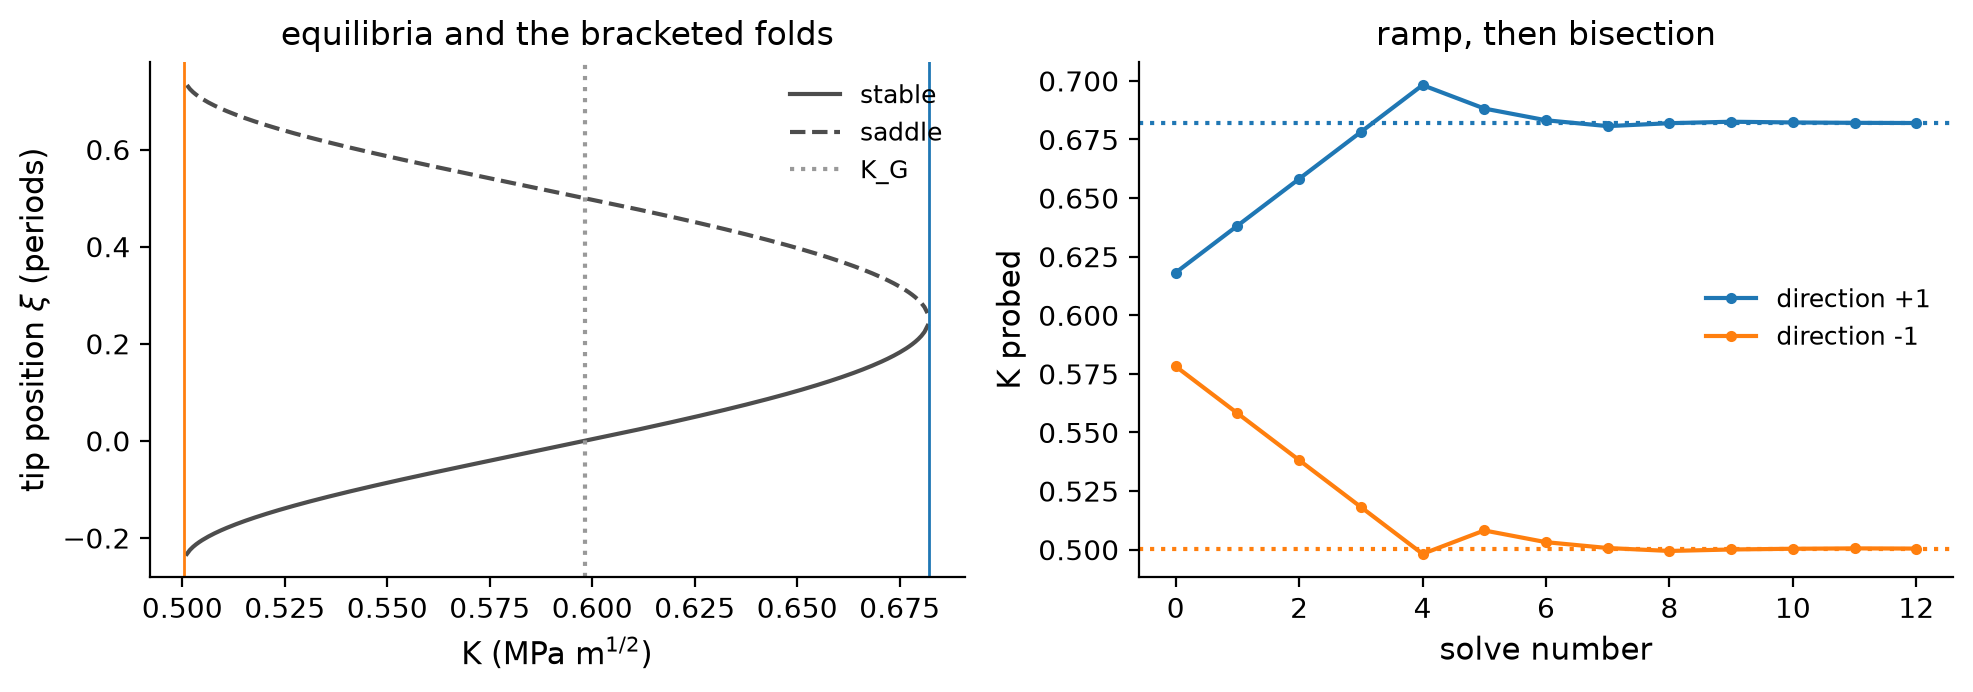

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
k = np.linspace(0.75, 1.25, 400) * K_G
for branch in (0, 1):                      # stable and unstable equilibria, one period
    arg = np.clip(-(1 - (k / K_G) ** 2) / W, -1, 1)
    xi = np.arcsin(arg) / (2 * np.pi) if branch == 0 else 0.5 - np.arcsin(arg) / (2 * np.pi)
    inside = np.abs((k / K_G) ** 2 - 1) <= W
    axes[0].plot(k[inside], xi[inside], "-" if branch == 0 else "--", color="0.3",
                 label="stable" if branch == 0 else "saddle")
for r, colour in [(up, "C0"), (down, "C1")]:
    h = pd.DataFrame(r["history"])
    axes[0].axvline(r["fold"], color=colour, lw=1)
    axes[1].plot(range(len(h)), h.load, ".-", color=colour,
                 label=f"direction {'+1' if r is up else '-1'}")
axes[0].axvline(K_G, color="0.6", ls=":", label="K_G")
axes[0].set(xlabel="K (MPa m$^{1/2}$)", ylabel="tip position $\\xi$ (periods)",
            title="equilibria and the bracketed folds")
axes[0].legend(frameon=False, fontsize=9)
axes[1].axhline(exact["K+"], color="C0", ls=":"); axes[1].axhline(exact["K-"], color="C1", ls=":")
axes[1].set(xlabel="solve number", ylabel="K probed", title="ramp, then bisection")
axes[1].legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

**Reading it.** Both folds land within the requested $10^{-4}$ of the closed
form $K_G\sqrt{1 \pm w}$, in about a dozen solves each: a coarse ramp (the
staircase on the right), then bisection. Between $K_-$ and $K_+$ the crack is
trapped: the Griffith load sits inside the range, and neither advance nor
healing happens at it. In a real calculation one runs exactly these two
calls, with `solve` a relaxation of the crack cluster, the state its positions
(plus any far-field amplitude) and `observable` the crack-tip position.

### Pitfall: a solver that does not say it failed, and a `jump` that is too large

`bracket_fold` decides "off the branch" from two signals: the solver's
convergence flag, and how far the state moved. A solver that returns only a
state — say, a fixed number of descent steps — removes the first signal.
Beyond the fold it then returns a state that has drifted downhill by an amount
that depends on how long it ran, not on the physics. With `jump` a fraction
of a lattice period that drift is still caught; with `jump` larger than a
period it is not, and the "fold" moves to wherever the drift per probe happens
to exceed `jump`.

In [12]:
def solve_no_flag(K, guess, iters=200):
    """Fixed number of descent steps, no convergence report."""
    xi = float(np.asarray(guess).ravel()[0])
    for _ in range(iters):
        xi -= 0.02 * gradient(xi, K)
    return np.array([xi])


for jump in (0.25, 2.0):
    r = mv.mech.bracket_fold(solve_no_flag, K_G, seed, step=0.02, jump=jump,
                             resolution=1e-4, direction=+1, max_load=2 * K_G)
    fold = r["fold"] if r["found"] else float("nan")
    print(f"jump = {jump:4.2f} period: fold {fold:.4f}  (exact K+ {exact['K+']:.4f}, "
          f"error {100 * (fold / exact['K+'] - 1):+.1f} %)")

jump = 0.25 period: fold 0.6882  (exact K+ 0.6821, error +0.9 %)
jump = 2.00 period: fold 0.7527  (exact K+ 0.6821, error +10.4 %)


With `jump = 0.25` the unflagged solver still brackets $K_+$ to about one
per cent (the drift is caught as soon as it exceeds a quarter
period; it overshoots slightly because the last few "on-branch" states are
not equilibria). With `jump = 2` the upper fold is placed well above $K_+$:
the crack had already left its cell, but the state had not moved two periods
within the solver's budget. Rules that follow: return `(state, converged)`
from `solve`; choose `jump` well above the smooth drift of the state per load
step and below the size of the event — for a crack, a fraction of the lattice
period; and check that the fold does not move when the solver's tolerance and
`step` are tightened.

## Summary

| quantity | function | result here (Si, Tersoff T3) |
|---|---|---|
| relaxed-ion $C_{11}, C_{12}, C_{44}$ | `elastic_constants` | 143, 75, 69 GPa (clamped $C_{44}$ 119) |
| lowest (111) cleavage | `cleavage_energies` | shuffle cut, ~1.2 J/m² (glide ~4.1) |
| Griffith load, (111)$[1\bar10]$ | LEFM with the two above | ~0.60 MPa m$^{1/2}$ |
| forces / stress audited | `check_gradient` | agreement to $10^{-6}$ |
| trapping range of a model crack | `bracket_fold` | $K_\pm$ to $10^{-4}$ of the closed form |

**Pitfalls collected.** Relax the reference lattice first. Use relaxed-ion
constants for any continuum coupled to atoms. Enumerate cleavage terminations
instead of assuming one. Check every hand-written derivative at two step
sizes. Make the continuation solver report convergence, and choose `jump`
between the smooth drift and the size of the event.

In [13]:
print(f"notebook executed in {time.time() - T_START:.1f} s")

notebook executed in 11.6 s


## References

- A. A. Griffith, *Phil. Trans. R. Soc. A* 221, 163 (1921) — the energy balance.
- G. C. Sih, P. C. Paris, G. R. Irwin, *Int. J. Fract. Mech.* 1, 189 (1965) —
  cracks in rectilinearly anisotropic bodies; S. G. Lekhnitskii, *Theory of
  Elasticity of an Anisotropic Body* (Holden-Day, 1963).
- R. Thomson, C. Hsieh, V. Rana, *J. Appl. Phys.* 42, 3154 (1971) — lattice
  trapping.
- J. E. Sinclair, *Phil. Mag.* 31, 647 (1975) — atomistic cracks with a
  flexible boundary.
- L. Kleinman, *Phys. Rev.* 128, 2614 (1962) — internal strain in diamond
  lattices; M. Born, K. Huang, *Dynamical Theory of Crystal Lattices* (Oxford,
  1954) — Cauchy–Born and inner displacements.
- J. Tersoff, *Phys. Rev. B* 38, 9902 (1988) — the Si potential used here.
- J. R. Kermode *et al.*, *Nature* 455, 1224 (2008); *Phys. Rev. Lett.* 115,
  135501 (2015) — lattice trapping and crack fronts in silicon.
- E. L. Allgower, K. Georg, *Numerical Continuation Methods* (Springer, 1990) —
  continuation and turning points.